# Part A: Understanding and Reproducing Baseline



## A1. Understanding the Baseline Implementation

We use the [mamba-minimal](https://github.com/johnma2006/mamba-minimal) implementation of Mamba-1 to study how the model processes input sequences and maintains its hidden state. We focus on the selective state-space mechanism, particularly the roles of \(\Delta\), \(B\), and \(C\), and its limitations in long-range memory tracking.

### Setup

We first clone the original repository and install the required dependencies. The Git commit is recorded for reproducibility.

In [ ]:
%pip -q install einops
import os, subprocess
from pathlib import Path
repo = Path('/content/mamba-minimal')
if not repo.exists():
    subprocess.run(['git', 'clone', '-q', 'https://github.com/johnma2006/mamba-minimal.git', str(repo)], check=True)
os.chdir(repo)
print('Working directory:', Path.cwd())
print('Upstream commit:', subprocess.check_output(['git', 'rev-parse', 'HEAD'], text=True).strip())

Working directory: /content/mamba-minimal
Upstream commit: 03de542a36d873f6e6c4057ad687278cc6ae944d


**A1.1 How event inputs propagate through the model and influence its hidden state**

- We first define the model configuration using the `ModelArgs` dataclass, which specifies parameters such as `d_model`, `d_state`, `n_layer`, and `expand`. During initialization, `__post_init__()` computes `d_inner`, `dt_rank`, and the padded vocabulary size. The resulting configuration is passed to the `Mamba` class.


- The input events are represented as token IDs of shape $(B,T)$. In `Mamba.forward()`, the embedding layer converts these tokens into continuous representations, which pass through the residual Mamba blocks, final RMSNorm, and language modeling head.

$$
(B,T)\xrightarrow{\text{Embedding}}(B,T,d_{\text{model}})
\xrightarrow{\text{Residual Blocks}}(B,T,d_{\text{model}})
\xrightarrow{\text{RMSNorm}}(B,T,d_{\text{model}})
\xrightarrow{\text{LM Head}}(B,T,V)
$$

Here, $V$ is the padded vocabulary size in the original implementation.


- In `ResidualBlock.forward()`, the operation `self.mixer(self.norm(x)) + x` applies RMSNorm before the Mamba block and adds the original input through a residual connection. Inside `MambaBlock.forward()`, `in_proj` splits the representation into two branches of dimension $d_{\text{inner}}=\text{expand}\times d_{\text{model}}$. The first branch passes through causal Conv1D, SiLU, and `ssm()`. The SSM output is multiplied by `SiLU(res)` from the second branch, followed by `out_proj`, which maps it back to $d_{\text{model}}$.

- The recurrent memory update takes place in `selective_scan()`, called from `ssm()`. The implementation initializes the hidden state to zero and updates it sequentially using:

$$
h_t=e^{\Delta_t A}\odot h_{t-1}+\Delta_t B_tu_t
$$

$$
y_t=C_th_t+Du_t
$$

  In the code, `x = deltaA[:, i] * x + deltaB_u[:, i]` implements the state update, while the multiplication with `C[:, i, :]` and summation over the state dimension produces the output. The outputs are stacked, and the direct term `u * D` is added. Since each update uses the previous hidden state, information from earlier SET events can influence later QUERY predictions.

**A1.2 What do the input-dependent parameters $\Delta$, $B$, and $C$ do?**

Unlike $A$ and $D$, which are learned but shared across timesteps, $\Delta$, $B$, and $C$ are generated from the input representations.

In `ssm()`, `x_proj` maps the input to `dt_rank + 2*d_state` features. The result is split into three parts using `split([dt_rank, n, n])`, producing a low-rank representation of $\Delta$, along with $B$ and $C$. The low-rank $\Delta$ is projected to $d_{\text{inner}}$ using `dt_proj`, followed by Softplus to ensure positive values.

- **$\Delta_t$:** Controls the decay of the previous hidden state through $e^{\Delta_t A}$ and also scales the new state update through $\Delta_t B_tu_t$.
- **$B_t$:** Determines how the current input contributes to the hidden state. In `selective_scan()`, it appears in `deltaB_u`, which is added during each recurrent update.
- **$C_t$:** Determines how the updated hidden state contributes to the output. The code multiplies the state by `C[:, i, :]` and sums over the state dimension.

For our SET/QUERY task, these input-dependent parameters allow the model to learn different memory behaviors for SET, QUERY, and NOOP events. However, these behaviors are learned rather than explicitly enforced.


**A1.3 Why can state retention, overwrite correctness, and cross-key interference differ?**

These three cases require different behaviors from the recurrent hidden state $h_t$, which is updated at every timestep.

- **State retention:** Consider `SET(A,2) → NOOP → ... → NOOP → QUERY(A)`. The model should still predict 2. However, in `selective_scan()`, the previous hidden state is repeatedly multiplied by `deltaA`, computed as $e^{\Delta_t A}$. Since these decay factors lie between 0 and 1, stored information may gradually weaken over long intervals.

- **Overwrite correctness:** Consider `SET(A,2) → SET(A,3) → QUERY(A)`. The correct answer is 3. The state update `x = deltaA[:, i] * x + deltaB_u[:, i]` combines the previous state with new information rather than explicitly replacing an old key-value entry. The model must therefore learn to make the latest value dominate the earlier one.

- **Cross-key interference:** Consider `SET(A,2) → SET(B,4) → QUERY(A)`. The answer should remain 2. In `selective_scan()`, the same recurrent state `x`, representing $h_t$ with shape $(B,d_{\text{inner}},d_{\text{state}})$, is updated at each timestep. Since the code does not allocate separate memory slots to individual keys, updating B may affect information previously stored about A.

These cases can differ because retaining information, replacing outdated values, and preventing interference place different demands on the same state-update mechanism. They represent possible failure mechanisms rather than experimentally established causes of errors.



**A1.4 Which code paths would you modify, and which invariants must be preserved?**

The main modification points are `MambaBlock.ssm()` and `MambaBlock.selective_scan()`.

- **`ssm()`** generates the input-dependent parameters $\Delta$, $B$, and $C$ using `x_proj` and `dt_proj`. Modifying these projections could change how the model controls memory retention, updates, and readout.

- **`selective_scan()`** computes `deltaA` and `deltaB_u` and updates the recurrent hidden state. Modifying these operations could change how previous information is preserved and new information is incorporated.

Any modification should preserve causality, ensuring that the hidden state depends only on previous states and the current input. The recurrent updates must follow the original event order, and the modified SSM must remain compatible with the surrounding `MambaBlock` operations.




## A2. Build the Task Head and Training Loop

In [ ]:
%%writefile generate_dataset.py
#!/usr/bin/env python3
"""Generate reproducible SET / QUERY / NOOP data for Tiny Mamba-1.

Pure Python standard library; works in Google Colab or locally.

Output files are gzip-compressed JSON Lines, containing:
  sample_id, split, events, query_targets, probe_index, probe_gap,
  overwrite_count

Events are triples [op, key, value], unused fields are null.
The label at a query timestep is the current value or 0 for UNSET;
labels at all other positions are null (map to -100 for cross-entropy).
"""
import argparse
import gzip
import json
import random
from pathlib import Path

KEYS = "ABCDEFGH"
NUM_VALUES = 4
SPLITS = {
    "train": ((32, 128), 10601, "standard"),
    "val": ((32, 128), 10602, "standard"),
    "test_id": ((128, 128), 10603, "standard"),
    "test_ood_256": ((256, 256), 10604, "standard"),
    "test_ood_512": ((512, 512), 10605, "standard"),
    "stress_gap_512": ((512, 512), 10606, "gap"),
    "stress_overwrite_512": ((512, 512), 10607, "overwrite"),
}


def encode_event(event):
    """Map events to the 41-token vocabulary described in the assignment."""
    op, key, val = event
    if op == "NOOP":
        return 0
    if op == "SET":
        return 1 + KEYS.index(key) * NUM_VALUES + (val - 1)
    if op == "QUERY":
        return 33 + KEYS.index(key)
    raise ValueError(f"Unknown event: {event!r}")


def random_event(rng, exclude_key=None):
    available = [k for k in KEYS if k != exclude_key]
    p = rng.random()
    if p < 0.32:
        return ["SET", rng.choice(available), rng.randint(1, NUM_VALUES)]
    if p < 0.50:
        return ["QUERY", rng.choice(available), None]
    return ["NOOP", None, None]


def make_sequence(rng, length, mode, sample_index):
    focus = rng.choice(KEYS)
    probe_index = None
    overwrites = None

    if mode == "standard":
        events = [random_event(rng) for _ in range(length)]
        # Guarantee at least two query targets, including an uninitialized key.
        events[0] = ["QUERY", rng.choice(KEYS), None]
        events[-1] = ["QUERY", rng.choice(KEYS), None]

    elif mode == "gap":
        # Keep the focus key unchanged for the full remaining interval.
        events = [["SET", focus, rng.randint(1, NUM_VALUES)]]
        events.extend(random_event(rng, exclude_key=focus)
                      for _ in range(length - 2))
        events.append(["QUERY", focus, None])
        probe_index = length - 1

    elif mode == "overwrite":
        # 1, 2, 4, or 8 overwrites to the same key; hold out the final query.
        overwrites = (1, 2, 4, 8)[sample_index % 4]
        events = [random_event(rng, exclude_key=focus)
                  for _ in range(length)]
        write_positions = [0] + [int(1 + j * (length - 3) / overwrites)
                                  for j in range(1, overwrites + 1)]
        prev_val = None
        for pos in write_positions:
            choices = [v for v in range(1, NUM_VALUES + 1) if v != prev_val]
            prev_val = rng.choice(choices)
            events[pos] = ["SET", focus, prev_val]
        events[-1] = ["QUERY", focus, None]
        probe_index = length - 1
    else:
        raise ValueError(mode)

    state = {}
    latest_update = {}
    labels = []
    probe_gap = None
    for t, (op, key, val) in enumerate(events):
        if op == "SET":
            state[key] = val
            latest_update[key] = t
            labels.append(None)
        elif op == "QUERY":
            labels.append(state.get(key, 0))
            if t == probe_index and key in latest_update:
                probe_gap = t - latest_update[key]
        else:
            labels.append(None)

    return {
        "events": events,
        "query_targets": labels,
        "probe_index": probe_index,
        "probe_gap": probe_gap,
        "overwrite_count": overwrites,
    }


def generate(output_dir, preset, seed_offset=0):
    sizes = {
        "small": (1000, 200),
        "assignment": (4000, 500),
        "full": (50000, 5000),
    }
    n_train, n_other = sizes[preset]
    output_dir.mkdir(parents=True, exist_ok=True)
    manifest = {
        "task": "causal_key_value_tracking",
        "preset": preset,
        "keys": KEYS,
        "values": [1, 2, 3, 4],
        "unset_class": 0,
        "input_vocabulary_size": 41,
        "event_encoding": "NOOP=0, SET(A,1..4)=1..4,...,SET(H,1..4)=29..32, QUERY(A..H)=33..40",
        "non_query_label": None,
        "seed_offset": seed_offset,
        "splits": {},
    }

    for split, (lengths, seed, mode) in SPLITS.items():
        count = n_train if split == "train" else n_other
        rng = random.Random(seed + seed_offset)
        path = output_dir / f"{split}.jsonl.gz"
        with gzip.open(path, "wt", encoding="utf-8", compresslevel=5) as f:
            for i in range(count):
                n = rng.randint(*lengths)
                item = make_sequence(rng, n, mode, i)
                item = {"sample_id": f"{split}_{i:06d}", "split": split, **item}
                f.write(json.dumps(item, separators=(",", ":")) + "\n")
        manifest["splits"][split] = {
            "count": count,
            "lengths": list(lengths),
            "seed": seed + seed_offset,
            "mode": mode,
            "filename": path.name,
        }
        print(f"{split:>21}: {count:>5} sequences -> {path.name}")

    with (output_dir / "manifest.json").open("w", encoding="utf-8") as f:
        json.dump(manifest, f, indent=2)
    print(f"Total: {n_train + n_other * (len(SPLITS) - 1):,} sequences")


if __name__ == "__main__":
    ap = argparse.ArgumentParser(description=__doc__)
    ap.add_argument("--preset", choices=["small", "assignment", "full"],
                    default="assignment")
    ap.add_argument("--output-dir", type=Path, default=Path("dataset"))
    ap.add_argument("--seed-offset", type=int, default=0,
                    help="Optional offset for a separate private test generation")
    args = ap.parse_args()
    generate(args.output_dir, args.preset, args.seed_offset)

Writing generate_dataset.py


In [ ]:
!python generate_dataset.py --preset assignment --output-dir dataset

                train:  4000 sequences -> train.jsonl.gz
                  val:   500 sequences -> val.jsonl.gz
              test_id:   500 sequences -> test_id.jsonl.gz
         test_ood_256:   500 sequences -> test_ood_256.jsonl.gz
         test_ood_512:   500 sequences -> test_ood_512.jsonl.gz
       stress_gap_512:   500 sequences -> stress_gap_512.jsonl.gz
 stress_overwrite_512:   500 sequences -> stress_overwrite_512.jsonl.gz
Total: 7,000 sequences


## **Data Loading and Query-Only Target Masking**

In [ ]:
import gzip
import json
import torch
from torch.utils.data import Dataset, DataLoader
from generate_dataset import encode_event

class EventDataset(Dataset):
    def __init__(self, path):
        with gzip.open(path, "rt", encoding="utf-8") as f:
            self.records = [json.loads(line) for line in f]

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        record = self.records[idx]

        tokens = [encode_event(event) for event in record["events"]]

        # Only QUERY positions have labels; others are ignored.
        targets = [
            -100 if value is None else int(value)
            for value in record["query_targets"]
        ]

        return torch.tensor(tokens), torch.tensor(targets)


def collate(batch):
    batch_size = len(batch)
    max_len = max(len(tokens) for tokens, _ in batch)

    ids = torch.zeros((batch_size, max_len), dtype=torch.long)
    targets = torch.full((batch_size, max_len), -100, dtype=torch.long)

    for i, (tokens, labels) in enumerate(batch):
        n = len(tokens)
        ids[i, :n] = tokens
        targets[i, :n] = labels

    return ids, targets


train_loader = DataLoader(
    EventDataset("dataset/train.jsonl.gz"),
    batch_size=16,
    shuffle=True,
    collate_fn=collate
)

tokens, targets = next(iter(train_loader))

print("Input shape:", tokens.shape)
print("Target shape:", targets.shape)
print("Query positions:", (targets != -100).sum().item())

Input shape: torch.Size([16, 125])
Target shape: torch.Size([16, 125])
Query positions: 275


## **Task-Specific Mamba-1 Model (Five-Class Prediction Head)**

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from model import Mamba, ModelArgs

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class StateTracker(nn.Module):
    def __init__(self):
        super().__init__()

        self.backbone = Mamba(ModelArgs(
            d_model=32,
            n_layer=1,
            d_state=8,
            expand=2,
            d_conv=4,
            vocab_size=41
        ))

        self.head = nn.Linear(32, 5)

    def forward(self, tokens):
        x = self.backbone.embedding(tokens)

        for layer in self.backbone.layers:
            x = layer(x)

        x = self.backbone.norm_f(x)
        return self.head(x)

model = StateTracker().to(device)

print("Device:", device)
print("Parameters:", sum(p.numel() for p in model.parameters()))

Device: cuda
Parameters: 10149


## **Baseline Training and Evaluation Implementation**

In [ ]:
%%writefile run_baseline.py
#!/usr/bin/env python3
"""
Requires johnma2006/mamba-minimal (model.py) in the current directory.
Reads generated gzip JSONL from generate_dataset.py.
"""
from __future__ import annotations

import argparse
import collections
import csv
import gzip
import json
import random
import time
from pathlib import Path

import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader
from generate_dataset import encode_event
from model import Mamba, ModelArgs

SPLITS = (
    "train", "val", "test_id", "test_ood_256", "test_ood_512",
    "stress_gap_512", "stress_overwrite_512",
)



def bin_delay(value):
    if value is None:
        return "unseen"
    if value <= 4:
        return "1-4"
    if value <= 16:
        return "5-16"
    if value <= 64:
        return "17-64"
    if value <= 128:
        return "65-128"
    if value <= 256:
        return "129-256"
    return "257+"


def bin_interference(value):
    if value == 0:
        return "0"
    if value <= 2:
        return "1-2"
    if value <= 7:
        return "3-7"
    return "8+"


def process_sample(obj):
    """Independently replay events to check labels and derive query metadata."""
    tokens = []
    labels = []
    delay = {}
    interference = {}
    query_overwrites = {}
    state, last_set, writes = {}, {}, collections.Counter()
    total_writes = 0
    assert len(obj["events"]) == len(obj["query_targets"])
    for t, (ev, target) in enumerate(zip(obj["events"], obj["query_targets"])):
        op, key, val = ev
        tokens.append(encode_event(ev))
        if op == "SET":
            assert target is None
            state[key] = val
            last_set[key] = (t, total_writes)
            writes[key] += 1
            total_writes += 1
            labels.append(-100)
        elif op == "QUERY":
            correct = state.get(key, 0)
            assert target == correct, f"Oracle mismatch at {obj.get('sample_id')} t={t}"
            labels.append(int(target))
            delay[t] = t - last_set[key][0] if key in last_set else None
            # Count other-key SET events strictly after last SET(key), or since start if unset.
            # total_writes includes the latest SET(key), so subtract 1 from that base.
            interference[t] = (total_writes - last_set[key][1] - 1) if key in last_set else total_writes
            query_overwrites[t] = max(0, writes[key] - 1)
        else:
            assert op == "NOOP" and target is None
            labels.append(-100)
    assert all(0 <= token <= 40 for token in tokens)
    assert any(x != -100 for x in labels)
    return {
        "tokens": tokens,
        "labels": labels,
        "delay": delay,
        "interference": interference,
        "query_overwrites": query_overwrites,
        "probe_index": obj["probe_index"],
        "overwrite_count": obj["overwrite_count"],
        "sample_id": obj["sample_id"],
    }


class EventDataset(Dataset):
    def __init__(self, path):
        with gzip.open(path, "rt", encoding="utf-8") as f:
            self.records = [json.loads(line) for line in f]

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        record = self.records[idx]

        tokens = [encode_event(event) for event in record["events"]]

        # Only QUERY positions have labels; others are ignored.
        targets = [
            -100 if value is None else int(value)
            for value in record["query_targets"]
        ]

        return torch.tensor(tokens), torch.tensor(targets)


def collate(batch):
    batch_size = len(batch)
    max_len = max(len(tokens) for tokens, _ in batch)

    ids = torch.zeros((batch_size, max_len), dtype=torch.long)
    targets = torch.full((batch_size, max_len), -100, dtype=torch.long)

    for i, (tokens, labels) in enumerate(batch):
        n = len(tokens)
        ids[i, :n] = tokens
        targets[i, :n] = labels

    return ids, targets


class StateTracker(nn.Module):
    def __init__(self):
        super().__init__()

        self.backbone = Mamba(ModelArgs(
            d_model=32,
            n_layer=1,
            d_state=8,
            expand=2,
            d_conv=4,
            vocab_size=41
        ))

        self.head = nn.Linear(32, 5)

    def forward(self, tokens):
        x = self.backbone.embedding(tokens)

        for layer in self.backbone.layers:
            x = layer(x)

        x = self.backbone.norm_f(x)
        return self.head(x)


def seed_everything(seed):
    random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)



def majority_label(dataset):
    counts = collections.Counter(y for rec in dataset.records for y in rec["query_targets"] if y is not None)
    return counts.most_common(1)[0][0]


def evaluate(model, loader, device, split, constant_class, output_dir):
    model.eval()
    groups = collections.defaultdict(lambda: [0, 0])
    overall_correct = overall_total = constant_correct = 0
    probe_correct = probe_total = 0
    t0 = time.perf_counter()
    seen = 0
    with torch.inference_mode():
        for ids, targets in loader:
            predictions = model(ids.to(device)).argmax(dim=-1).cpu()
            # Evaluation loaders are unshuffled; align metadata to each batch.
            records = loader.dataset.records[seen:seen + ids.size(0)]
            seen += ids.size(0)
            for i, raw_record in enumerate(records):
                rec = process_sample(raw_record)
                for t, true in enumerate(rec["labels"]):
                    if true == -100:
                        continue
                    pred = int(predictions[i, t])
                    good = int(pred == true)
                    overall_correct += good
                    overall_total += 1
                    constant_correct += int(constant_class == true)
                    buckets = (
                        ("delay", bin_delay(rec["delay"][t])),
                        ("cross_key_interference", bin_interference(rec["interference"][t])),
                        ("overwrites_to_date", str(rec["query_overwrites"][t])),
                        ("sequence_length", str(len(rec["tokens"]))),
                    )
                    for name, bucket in buckets:
                        groups[(name, bucket)][0] += good
                        groups[(name, bucket)][1] += 1
                    if rec["probe_index"] is not None and t == rec["probe_index"]:
                        probe_correct += good
                        probe_total += 1
                        if rec["overwrite_count"] is not None:
                            key = ("overwrite_stress_probes", str(rec["overwrite_count"]))
                            groups[key][0] += good
                            groups[key][1] += 1
                        if rec["delay"][t] is not None:
                            key = ("stress_probe_delay", bin_delay(rec["delay"][t]))
                            groups[key][0] += good
                            groups[key][1] += 1
    secs = time.perf_counter() - t0
    report = {
        "split": split,
        "num_sequences": len(loader.dataset),
        "num_queries": overall_total,
        "query_accuracy": overall_correct / overall_total,
        "constant_label": constant_class,
        "constant_accuracy": constant_correct / overall_total,
        "oracle_accuracy": 1.0,  # Generator labels are validated via independent event replay.
        "probe_accuracy": probe_correct / probe_total if probe_total else None,
        "num_probes": probe_total,
        "evaluation_seconds": round(secs, 2),
        "queries_per_second": round(overall_total / secs, 1) if secs > 0 else None,
    }
    output_dir.mkdir(parents=True, exist_ok=True)
    (output_dir / f"metrics_{split}.json").write_text(json.dumps(report, indent=2))
    with (output_dir / f"groups_{split}.csv").open("w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow(["split", "metric", "group", "correct", "count", "accuracy"])
        for (name, bucket), (correct, total) in sorted(groups.items()):
            writer.writerow([split, name, bucket, correct, total, correct / total])
    print(f"{split:>22} | query acc {report['query_accuracy']:.4f} | "
          f"majority {report['constant_accuracy']:.4f} | oracle 1.0000"
          + (f" | focused-probe {report['probe_accuracy']:.4f}" if probe_total else "")
          + f" | {secs:.1f}s")
    return report


def run(args):
    seed_everything(args.seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    if args.device != "auto":
        device = torch.device(args.device)
    print(f"Device: {device}, torch: {torch.__version__}, seed: {args.seed}")
    model = StateTracker().to(device)
    count = sum(p.numel() for p in model.parameters())
    print(f"Original Mamba-1 + five-class head | parameters: {count:,} | FP32")
    data_dir = args.data_dir
    train_ds = EventDataset(data_dir / "train.jsonl.gz")
    most_common = majority_label(train_ds)
    print(f"Train samples: {len(train_ds)}, training majority class: {most_common}")
    if args.checkpoint:
        ckpt = torch.load(args.checkpoint, map_location="cpu", weights_only=True)
        model.load_state_dict(ckpt["model_state"])
        print(f"Loaded checkpoint at {args.checkpoint} (step {ckpt['step']})")
    elif not args.eval_only:
        loader = DataLoader(train_ds, batch_size=args.batch_size, shuffle=True,
                            collate_fn=collate, num_workers=0)
        iterator = iter(loader)
        optimizer = torch.optim.AdamW(model.parameters(), lr=args.lr)
        t0 = time.perf_counter()
        model.train()
        for step in range(1, args.steps + 1):
            try:
                ids, targets = next(iterator)
            except StopIteration:
                iterator = iter(loader)
                ids, targets = next(iterator)
            ids, targets = ids.to(device), targets.to(device)
            optimizer.zero_grad(set_to_none=True)
            logits = model(ids)
            loss = F.cross_entropy(logits.reshape(-1, 5), targets.reshape(-1), ignore_index=-100)
            loss.backward()
            optimizer.step()
            if step == 1 or step % args.log_every == 0 or step == args.steps:
                with torch.no_grad():
                    mask = targets != -100
                    accuracy = (logits.argmax(-1)[mask] == targets[mask]).float().mean().item()
                print(f"step {step:>4}/{args.steps} | loss {loss.item():.4f} | batch_query_acc {accuracy:.3f} | elapsed {time.perf_counter()-t0:.1f}s")
        args.output_dir.mkdir(parents=True, exist_ok=True)
        torch.save({"model_state": model.state_dict(), "step": args.steps,
                    "seed": args.seed, "config": {"d_model": 32, "d_state": 8,
                    "n_layer": 1, "expand": 2, "d_conv": 4, "lr": args.lr,
                    "batch_size": args.batch_size, "precision": "FP32"}},
                   args.output_dir / "baseline.pt")
        print(f"Saved checkpoint: {args.output_dir / 'baseline.pt'}")
    else:
        raise ValueError("--eval-only requires --checkpoint")
    for split in args.eval_splits:
        dataset = EventDataset(data_dir / f"{split}.jsonl.gz")
        eval_loader = DataLoader(dataset, batch_size=args.eval_batch_size,
                                 shuffle=False, collate_fn=collate, num_workers=0)
        evaluate(model, eval_loader, device, split, most_common, args.output_dir)


if __name__ == "__main__":
    p = argparse.ArgumentParser(description=__doc__)
    p.add_argument("--data-dir", type=Path, default=Path("dataset"))
    p.add_argument("--output-dir", type=Path, default=Path("results"))
    p.add_argument("--steps", type=int, default=250)
    p.add_argument("--batch-size", type=int, default=16)
    p.add_argument("--eval-batch-size", type=int, default=4)
    p.add_argument("--lr", type=float, default=0.001)
    p.add_argument("--seed", type=int, default=42)
    p.add_argument("--log-every", type=int, default=25)
    p.add_argument("--device", choices=["auto", "cpu", "cuda", "mps"], default="auto")
    p.add_argument("--eval-splits", nargs="+", choices=SPLITS,
                   default=["val", "test_id"])
    p.add_argument("--checkpoint", type=Path, default=None)
    p.add_argument("--eval-only", action="store_true")
    run(p.parse_args())

Writing run_baseline.py


### **250 steps run**

In [ ]:
!python run_baseline.py --steps 250 --batch-size 16 --lr 0.001 --seed 42 --output-dir results/seed42_baseline_250 --eval-splits val test_id

Device: cuda, torch: 2.14.1+cu130, seed: 42
Original Mamba-1 + five-class head | parameters: 10,149 | FP32
Train samples: 4000, training majority class: 0
step    1/250 | loss 1.8179 | batch_query_acc 0.183 | elapsed 4.7s
step   25/250 | loss 1.6140 | batch_query_acc 0.317 | elapsed 8.3s
step   50/250 | loss 1.6033 | batch_query_acc 0.325 | elapsed 10.9s
step   75/250 | loss 1.5695 | batch_query_acc 0.314 | elapsed 13.2s
step  100/250 | loss 1.5442 | batch_query_acc 0.331 | elapsed 15.5s
step  125/250 | loss 1.5478 | batch_query_acc 0.326 | elapsed 17.8s
step  150/250 | loss 1.5404 | batch_query_acc 0.323 | elapsed 20.4s
step  175/250 | loss 1.5937 | batch_query_acc 0.247 | elapsed 23.1s
step  200/250 | loss 1.5204 | batch_query_acc 0.326 | elapsed 25.4s
step  225/250 | loss 1.5399 | batch_query_acc 0.292 | elapsed 27.7s
step  250/250 | loss 1.4757 | batch_query_acc 0.356 | elapsed 29.9s
Saved checkpoint: results/seed42_baseline_250/baseline.pt
                   val | query acc 0.3447

The initial 250-step baseline achieved accuracy only slightly above the majority-class baseline. We therefore extended training to 2,000 updates.

### **2000 steps run**

In [ ]:
!python run_baseline.py --steps 2000 --batch-size 16 --lr 0.001 --seed 42 --output-dir results/seed42_baseline_2000 --eval-splits val test_id test_ood_256 test_ood_512 stress_gap_512 stress_overwrite_512

Device: cuda, torch: 2.14.1+cu130, seed: 42
Original Mamba-1 + five-class head | parameters: 10,149 | FP32
Train samples: 4000, training majority class: 0
step    1/2000 | loss 1.8179 | batch_query_acc 0.183 | elapsed 4.7s
step   25/2000 | loss 1.6140 | batch_query_acc 0.317 | elapsed 7.9s
step   50/2000 | loss 1.6033 | batch_query_acc 0.325 | elapsed 10.5s
step   75/2000 | loss 1.5695 | batch_query_acc 0.314 | elapsed 12.9s
step  100/2000 | loss 1.5442 | batch_query_acc 0.331 | elapsed 15.4s
step  125/2000 | loss 1.5478 | batch_query_acc 0.326 | elapsed 17.8s
step  150/2000 | loss 1.5404 | batch_query_acc 0.323 | elapsed 20.6s
step  175/2000 | loss 1.5937 | batch_query_acc 0.247 | elapsed 23.2s
step  200/2000 | loss 1.5204 | batch_query_acc 0.326 | elapsed 25.6s
step  225/2000 | loss 1.5399 | batch_query_acc 0.292 | elapsed 27.9s
step  250/2000 | loss 1.4757 | batch_query_acc 0.356 | elapsed 30.2s
step  275/2000 | loss 1.4437 | batch_query_acc 0.408 | elapsed 32.9s
step  300/2000 | lo

## **A3. Establish the Baseline**

In [ ]:
import json
import pandas as pd

results_dir = "results/seed42_baseline_2000"

splits = [
    "val", "test_id", "test_ood_256",
    "test_ood_512", "stress_gap_512",
    "stress_overwrite_512"
]

results = [
    json.load(open(f"{results_dir}/metrics_{split}.json"))
    for split in splits
]

df = pd.DataFrame(results)

table = df[[
    "split", "query_accuracy",
    "constant_accuracy", "oracle_accuracy",
    "probe_accuracy"
]].round(4)

table = table.rename(columns={
    "constant_accuracy": "majority_accuracy",
    "probe_accuracy": "stress_probe_accuracy"
})

display(table.fillna("N/A"))

,split,query_accuracy,majority_accuracy,oracle_accuracy,stress_probe_accuracy
0,val,0.8831,0.3351,1.0,N/A
1,test_id,0.8474,0.2328,1.0,N/A
2,test_ood_256,0.8141,0.1128,1.0,N/A
3,test_ood_512,0.8034,0.0597,1.0,N/A
4,stress_gap_512,0.7965,0.0421,1.0,0.218
5,stress_overwrite_512,0.7992,0.0428,1.0,0.942


## **A4. Failure Diagnosis and Hypotheses**

## **Failure Diagnosis**

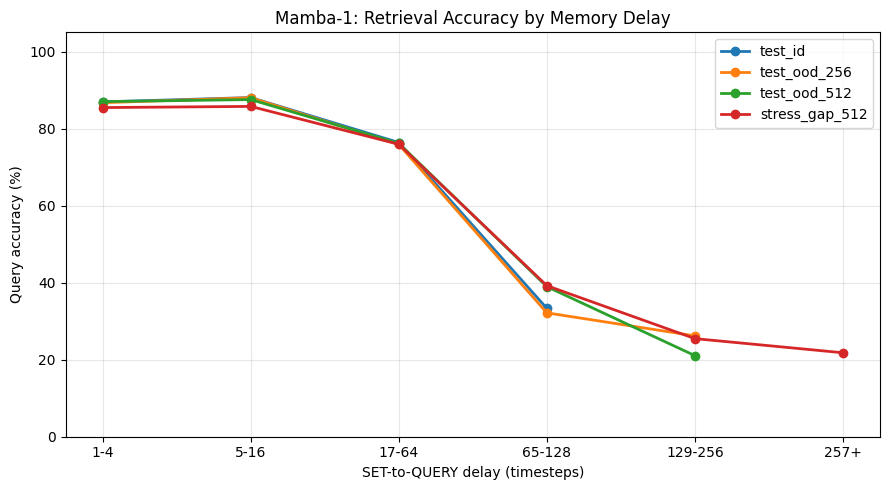

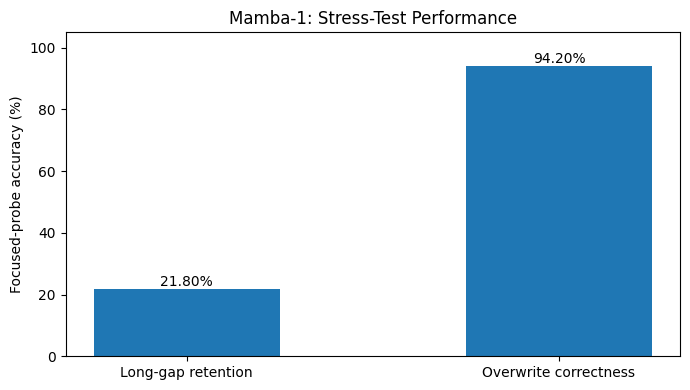

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import json
from pathlib import Path

output = Path("results/seed42_baseline_2000")

# Plot 1: Retrieval accuracy across SET-to-QUERY delays

delay_bins = ["1-4", "5-16", "17-64", "65-128", "129-256", "257+"]
splits = ["test_id", "test_ood_256", "test_ood_512", "stress_gap_512"]

plt.figure(figsize=(9, 5))

for split in splits:
    df = pd.read_csv(output / f"groups_{split}.csv")
    df = df[df["metric"] == "delay"].set_index("group")

    accuracy = [
        df.loc[b, "accuracy"] * 100
        if b in df.index and df.loc[b, "count"] >= 30
        else float("nan")
        for b in delay_bins
    ]

    plt.plot(delay_bins, accuracy, marker="o", linewidth=2, label=split)

plt.xlabel("SET-to-QUERY delay (timesteps)")
plt.ylabel("Query accuracy (%)")
plt.title("Mamba-1: Retrieval Accuracy by Memory Delay")
plt.ylim(0, 105)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(output / "baseline_delay_accuracy.png", dpi=300)
plt.show()


# Plot 2: Focused-probe accuracy on stress tests

probe_splits = ["stress_gap_512", "stress_overwrite_512"]
probe_names = ["Long-gap retention", "Overwrite correctness"]

probe_scores = []

for split in probe_splits:
    with open(output / f"metrics_{split}.json") as f:
        metrics = json.load(f)
    probe_scores.append(metrics["probe_accuracy"] * 100)

plt.figure(figsize=(7, 4))

bars = plt.bar(probe_names, probe_scores, width=0.5)

for bar, score in zip(bars, probe_scores):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        score + 1,
        f"{score:.2f}%",
        ha="center"
    )

plt.ylabel("Focused-probe accuracy (%)")
plt.title("Mamba-1: Stress-Test Performance")
plt.ylim(0, 105)
plt.tight_layout()
plt.savefig(output / "baseline_stress_accuracy.png", dpi=300)
plt.show()

### **Plot 1: Retrieval Accuracy by Memory Delay**

Retrieval accuracy declines sharply as the distance between SET and QUERY increases. This pattern is consistent across the evaluation splits, indicating that Mamba-1 handles short-range retrieval relatively well but struggles to preserve information over longer intervals. Overall accuracy therefore masks substantial long-term memory failures.

### **Plot 2: Long-Gap and Overwrite Stress Tests**

Both stress tests use sequences of length 512, with one designated final QUERY per sequence. The long-gap test shows poor retrieval when a value must be retained from the beginning of the sequence. In contrast, the overwrite test shows strong performance because the latest SET occurs immediately before the final QUERY. This indicates that Mamba-1 handles recent updates effectively but struggles with long-term retention.

## **Hypothesis**

- **Hypothesis 1:** Long-Horizon Retention

Retrieval accuracy decreases as the distance between the latest SET and its corresponding QUERY increases. This hypothesis can be tested by comparing query accuracy across different SET-to-QUERY delay ranges.

- **Hypothesis 2:** Coupled Retention and Writing

In Mamba-1, the input-dependent $\Delta_t$ controls both previous-state decay and the contribution of new information. This coupling may limit long-term retention. Introducing a learned retention gate could improve long-delay retrieval while preserving overwrite correctness.

# **Part B — Implement One Research Improvement**

We introduce an input-dependent retention gate $r_t = \sigma(W_r u_t + b_r)$ to control state decay separately from the input-write term. The modified recurrence is

$$
h_t = e^{r_t \Delta_t A}\odot h_{t-1} + \Delta_t B_t u_t.
$$

The gate is implemented using `nn.Linear(d_inner, 1, bias=True)` followed by a sigmoid activation. With $d_{\text{inner}}=32\times2=64$, this projection maps 64 input features to one scalar, adding 64 weights and one bias (65 learnable parameters). The remaining Mamba-1 architecture and training configuration are unchanged.

In [ ]:
%%writefile model_retention.py
"""Retention-gated variant of the original Mamba-1 implementation.

The learned gate modifies state decay while leaving the input-write
term unchanged.

Ablation modes:
    MAMBA_DISABLE_RETENTION=1  -> gate fixed at 1
    MAMBA_FIXED_RETENTION=0.5  -> gate fixed at 0.5
"""

import os

import torch
import torch.nn as nn
import torch.nn.functional as F

from model import Mamba as OriginalMamba
from model import MambaBlock as OriginalMambaBlock
from model import ModelArgs
from einops import einsum


class RetentionMambaBlock(OriginalMambaBlock):
    def __init__(self, args: ModelArgs):
        super().__init__(args)

        self.retention_proj = nn.Linear(args.d_inner, 1, bias=True)

        # Initialize close to the original recurrence.
        nn.init.zeros_(self.retention_proj.weight)
        nn.init.constant_(self.retention_proj.bias, 3.0)

        self.disable_retention = (
            os.getenv("MAMBA_DISABLE_RETENTION", "0") == "1"
        )

        fixed = os.getenv("MAMBA_FIXED_RETENTION")
        self.fixed_retention = float(fixed) if fixed is not None else None

        if self.fixed_retention is not None and not (
            0.0 < self.fixed_retention <= 1.0
        ):
            raise ValueError(
                "MAMBA_FIXED_RETENTION must be in (0, 1]"
            )

        if self.disable_retention and self.fixed_retention is not None:
            raise ValueError(
                "Do not set DISABLE_RETENTION and FIXED_RETENTION together"
            )

    def selective_scan(self, u, delta, A, B, C, D):
        batch, length, inner = u.shape
        state_dim = A.shape[1]

        if self.disable_retention:
            r = torch.ones_like(delta[..., :1])
        elif self.fixed_retention is not None:
            r = torch.full_like(delta[..., :1], self.fixed_retention)
        else:
            r = torch.sigmoid(self.retention_proj(u))

        # Only modification: gate the state-decay term.
        deltaA = torch.exp(
            einsum(delta * r, A, 'b l d_in, d_in n -> b l d_in n')
        )

        # Original Mamba input-write computation.
        deltaB_u = einsum(
            delta, B, u,
            'b l d_in, b l n, b l d_in -> b l d_in n'
        )

        state = torch.zeros((batch, inner, state_dim), device=deltaA.device)
        ys = []

        for i in range(length):
            state = deltaA[:, i] * state + deltaB_u[:, i]
            y_i = einsum(state, C[:, i, :], 'b d_in n, b n -> b d_in')
            ys.append(y_i)

        y = torch.stack(ys, dim=1)
        return y + u * D

class Mamba(OriginalMamba):
    def __init__(self, args: ModelArgs):
        super().__init__(args)

        # Preserve original weights and main RNG sequence.
        with torch.random.fork_rng(devices=[]):
            for layer in self.layers:
                old_mixer = layer.mixer

                new_mixer = RetentionMambaBlock(args)

                new_mixer.load_state_dict(
                    old_mixer.state_dict(),
                    strict=False
                )

                layer.mixer = new_mixer

Writing model_retention.py


In [ ]:
%%writefile run_retention.py
#!/usr/bin/env python3
"""Training and evaluation of Mamba-1 with a learned retention gate.

Uses the original Mamba-1 backbone, a five-class prediction head,
and the SET/QUERY/NOOP dataset.
"""

import argparse
import collections
import csv
import gzip
import json
import random
import sys
import time
from pathlib import Path

import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Dataset
from generate_dataset import encode_event

SPLITS = (
    "train", "val", "test_id", "test_ood_256", "test_ood_512",
    "stress_gap_512", "stress_overwrite_512",
)


def bin_delay(value):
    if value is None:
        return "unseen"
    if value <= 4:
        return "1-4"
    if value <= 16:
        return "5-16"
    if value <= 64:
        return "17-64"
    if value <= 128:
        return "65-128"
    if value <= 256:
        return "129-256"
    return "257+"


def bin_interference(value):
    if value == 0:
        return "0"
    if value <= 2:
        return "1-2"
    if value <= 7:
        return "3-7"
    return "8+"


def process_sample(obj):
    """Independently replay events to check labels and derive query metadata."""
    tokens = []
    labels = []
    delay = {}
    interference = {}
    query_overwrites = {}
    state, last_set, writes = {}, {}, collections.Counter()
    total_writes = 0
    assert len(obj["events"]) == len(obj["query_targets"])
    for t, (ev, target) in enumerate(zip(obj["events"], obj["query_targets"])):
        op, key, val = ev
        tokens.append(encode_event(ev))
        if op == "SET":
            assert target is None
            state[key] = val
            last_set[key] = (t, total_writes)
            writes[key] += 1
            total_writes += 1
            labels.append(-100)
        elif op == "QUERY":
            correct = state.get(key, 0)
            assert target == correct, f"Oracle mismatch at {obj.get('sample_id')} t={t}"
            labels.append(int(target))
            delay[t] = t - last_set[key][0] if key in last_set else None
            # Count other-key SET events strictly after last SET(key), or since start if unset.
            # total_writes includes the latest SET(key), so subtract 1 from that base.
            interference[t] = (total_writes - last_set[key][1] - 1) if key in last_set else total_writes
            query_overwrites[t] = max(0, writes[key] - 1)
        else:
            assert op == "NOOP" and target is None
            labels.append(-100)
    assert all(0 <= token <= 40 for token in tokens)
    assert any(x != -100 for x in labels)
    return {
        "tokens": tokens,
        "labels": labels,
        "delay": delay,
        "interference": interference,
        "query_overwrites": query_overwrites,
        "probe_index": obj["probe_index"],
        "overwrite_count": obj["overwrite_count"],
        "sample_id": obj["sample_id"],
    }


class EventDataset(Dataset):
    def __init__(self, path):
        with gzip.open(path, "rt", encoding="utf-8") as f:
            self.records = [json.loads(line) for line in f]

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        record = self.records[idx]

        tokens = [encode_event(event) for event in record["events"]]

        # Only QUERY positions have labels; others are ignored.
        targets = [
            -100 if value is None else int(value)
            for value in record["query_targets"]
        ]

        return torch.tensor(tokens), torch.tensor(targets)


def collate(batch):
    batch_size = len(batch)
    max_len = max(len(tokens) for tokens, _ in batch)

    ids = torch.zeros((batch_size, max_len), dtype=torch.long)
    targets = torch.full((batch_size, max_len), -100, dtype=torch.long)

    for i, (tokens, labels) in enumerate(batch):
        n = len(tokens)
        ids[i, :n] = tokens
        targets[i, :n] = labels

    return ids, targets


class StateTracker(nn.Module):
    def __init__(self, repo_dir):
        super().__init__()
        sys.path.insert(0, str(repo_dir.resolve()))
        try:
            from model_retention import Mamba, ModelArgs
        except ImportError as e:
            raise ImportError("Cannot import upstream Mamba. Clone https://github.com/johnma2006/mamba-minimal and pass --repo-dir PATH") from e
        self.backbone = Mamba(ModelArgs(
            d_model=32, n_layer=1, d_state=8, expand=2,
            d_conv=4, vocab_size=41,
        ))
        # Reuse upstream embedding/layers/norm; do NOT call its tied 48-way LM head.
        self.head = nn.Linear(32, 5)

    def forward(self, token_ids):
        x = self.backbone.embedding(token_ids)
        for layer in self.backbone.layers:
            x = layer(x)
        return self.head(self.backbone.norm_f(x))


def seed_everything(seed):
    random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def validate_model(model, device):
    # Oracle tests: UNSET, overwrite, other key, and NOOP.
    obj = {"sample_id": "smoke", "probe_index": None, "overwrite_count": None,
           "events": [["QUERY", "A", None], ["SET", "A", 2], ["NOOP", None, None],
                      ["SET", "B", 4], ["QUERY", "A", None], ["SET", "A", 3],
                      ["QUERY", "A", None], ["QUERY", "B", None]],
           "query_targets": [0, None, None, None, 2, None, 3, 4]}
    rec = process_sample(obj)
    ids, labels = collate([(torch.tensor(rec["tokens"]), torch.tensor(rec["labels"]))])
    assert labels[0].tolist() == [0, -100, -100, -100, 2, -100, 3, 4]
    assert len(rec["tokens"]) == 8 and set(rec["tokens"]).issubset(set(range(41)))
    assert torch.equal((labels != -100), (ids >= 33))
    assert model.backbone.args.vocab_size == 48
    model.eval()
    with torch.no_grad():
        a = torch.tensor([[33, 1, 0, 34, 4, 33, 0, 0]], device=device)
        b = torch.tensor([[33, 1, 0, 34, 4, 33, 32, 40]], device=device)
        oa, ob = model(a), model(b)
        assert oa.shape == (1, 8, 5)
        assert torch.isfinite(oa).all()
        assert torch.allclose(oa[:, :6], ob[:, :6], atol=1e-5, rtol=1e-5), "Future tokens leaked into prefix logits"
    model.train()
    logits = model(ids.to(device))
    loss = F.cross_entropy(logits.reshape(-1, 5), labels.to(device).reshape(-1), ignore_index=-100)
    assert torch.isfinite(loss)
    loss.backward()
    assert all(p.grad is None or torch.isfinite(p.grad).all() for p in model.parameters())
    model.zero_grad(set_to_none=True)
    print("PASS: oracle, encoding, query-only mask, shapes, finite gradients, causal prefix")


def majority_label(dataset):
    counts = collections.Counter(y for rec in dataset.records for y in rec["query_targets"] if y is not None)
    return counts.most_common(1)[0][0]


def evaluate(model, loader, device, split, constant_class, output_dir):
    model.eval()
    groups = collections.defaultdict(lambda: [0, 0])
    overall_correct = overall_total = constant_correct = 0
    probe_correct = probe_total = 0
    t0 = time.perf_counter()
    seen = 0
    with torch.inference_mode():
        for ids, targets in loader:
            predictions = model(ids.to(device)).argmax(dim=-1).cpu()
            # Evaluation loaders are unshuffled; align metadata to each batch.
            records = loader.dataset.records[seen:seen + ids.size(0)]
            seen += ids.size(0)
            for i, raw_record in enumerate(records):
                rec = process_sample(raw_record)
                for t, true in enumerate(rec["labels"]):
                    if true == -100:
                        continue
                    pred = int(predictions[i, t])
                    good = int(pred == true)
                    overall_correct += good
                    overall_total += 1
                    constant_correct += int(constant_class == true)
                    buckets = (
                        ("delay", bin_delay(rec["delay"][t])),
                        ("cross_key_interference", bin_interference(rec["interference"][t])),
                        ("overwrites_to_date", str(rec["query_overwrites"][t])),
                        ("sequence_length", str(len(rec["tokens"]))),
                    )
                    for name, bucket in buckets:
                        groups[(name, bucket)][0] += good
                        groups[(name, bucket)][1] += 1
                    if rec["probe_index"] is not None and t == rec["probe_index"]:
                        probe_correct += good
                        probe_total += 1
                        if rec["overwrite_count"] is not None:
                            key = ("overwrite_stress_probes", str(rec["overwrite_count"]))
                            groups[key][0] += good
                            groups[key][1] += 1
                        if rec["delay"][t] is not None:
                            key = ("stress_probe_delay", bin_delay(rec["delay"][t]))
                            groups[key][0] += good
                            groups[key][1] += 1
    secs = time.perf_counter() - t0
    report = {
        "split": split,
        "num_sequences": len(loader.dataset),
        "num_queries": overall_total,
        "query_accuracy": overall_correct / overall_total,
        "constant_label": constant_class,
        "constant_accuracy": constant_correct / overall_total,
        "oracle_accuracy": 1.0,  # Generator labels are validated via independent event replay.
        "probe_accuracy": probe_correct / probe_total if probe_total else None,
        "num_probes": probe_total,
        "evaluation_seconds": round(secs, 2),
        "queries_per_second": round(overall_total / secs, 1) if secs > 0 else None,
    }
    output_dir.mkdir(parents=True, exist_ok=True)
    (output_dir / f"metrics_{split}.json").write_text(json.dumps(report, indent=2))
    with (output_dir / f"groups_{split}.csv").open("w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow(["split", "metric", "group", "correct", "count", "accuracy"])
        for (name, bucket), (correct, total) in sorted(groups.items()):
            writer.writerow([split, name, bucket, correct, total, correct / total])
    print(f"{split:>22} | query acc {report['query_accuracy']:.4f} | "
          f"majority {report['constant_accuracy']:.4f} | oracle 1.0000"
          + (f" | focused-probe {report['probe_accuracy']:.4f}" if probe_total else "")
          + f" | {secs:.1f}s")
    return report


def run(args):
    seed_everything(args.seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    if args.device != "auto":
        device = torch.device(args.device)
    print(f"Device: {device}, torch: {torch.__version__}, seed: {args.seed}")
    model = StateTracker(args.repo_dir).to(device)
    count = sum(p.numel() for p in model.parameters())
    print(f"Mamba-1 + retention-gated selective scan + five-class head | parameters: {count:,} | FP32")
    if args.smoke:
        validate_model(model, device)
        return
    data_dir = args.data_dir
    train_ds = EventDataset(data_dir / "train.jsonl.gz")
    most_common = majority_label(train_ds)
    print(f"Train samples: {len(train_ds)}, training majority class: {most_common}")
    if args.checkpoint:
        ckpt = torch.load(args.checkpoint, map_location="cpu", weights_only=True)
        model.load_state_dict(ckpt["model_state"])
        print(f"Loaded checkpoint at {args.checkpoint} (step {ckpt['step']})")
    elif not args.eval_only:
        loader = DataLoader(train_ds, batch_size=args.batch_size, shuffle=True,
                            collate_fn=collate, num_workers=0)
        iterator = iter(loader)
        optimizer = torch.optim.AdamW(model.parameters(), lr=args.lr)
        t0 = time.perf_counter()
        model.train()
        for step in range(1, args.steps + 1):
            try:
                ids, targets = next(iterator)
            except StopIteration:
                iterator = iter(loader)
                ids, targets = next(iterator)
            ids, targets = ids.to(device), targets.to(device)
            optimizer.zero_grad(set_to_none=True)
            logits = model(ids)
            loss = F.cross_entropy(logits.reshape(-1, 5), targets.reshape(-1), ignore_index=-100)
            loss.backward()
            optimizer.step()
            if step == 1 or step % args.log_every == 0 or step == args.steps:
                with torch.no_grad():
                    mask = targets != -100
                    accuracy = (logits.argmax(-1)[mask] == targets[mask]).float().mean().item()
                print(f"step {step:>4}/{args.steps} | loss {loss.item():.4f} | batch_query_acc {accuracy:.3f} | elapsed {time.perf_counter()-t0:.1f}s")
        args.output_dir.mkdir(parents=True, exist_ok=True)
        torch.save({"model_state": model.state_dict(), "step": args.steps,
                    "seed": args.seed, "config": {"d_model": 32, "d_state": 8,
                    "n_layer": 1, "expand": 2, "d_conv": 4, "lr": args.lr,
                    "batch_size": args.batch_size, "precision": "FP32"}},
                   args.output_dir / "retention.pt")
        print(f"Saved checkpoint: {args.output_dir / 'retention.pt'}")
    else:
        raise ValueError("--eval-only requires --checkpoint")
    for split in args.eval_splits:
        dataset = EventDataset(data_dir / f"{split}.jsonl.gz")
        eval_loader = DataLoader(dataset, batch_size=args.eval_batch_size,
                                 shuffle=False, collate_fn=collate, num_workers=0)
        evaluate(model, eval_loader, device, split, most_common, args.output_dir)


if __name__ == "__main__":
    p = argparse.ArgumentParser(description=__doc__)
    p.add_argument("--repo-dir", type=Path, default=Path("."))
    p.add_argument("--data-dir", type=Path, default=Path("dataset"))
    p.add_argument("--output-dir", type=Path, default=Path("results_retention"))
    p.add_argument("--steps", type=int, default=250)
    p.add_argument("--batch-size", type=int, default=16)
    p.add_argument("--eval-batch-size", type=int, default=4)
    p.add_argument("--lr", type=float, default=0.001)
    p.add_argument("--seed", type=int, default=42)
    p.add_argument("--log-every", type=int, default=25)
    p.add_argument("--device", choices=["auto", "cpu", "cuda", "mps"], default="auto")
    p.add_argument("--eval-splits", nargs="+", choices=SPLITS,
                   default=["val", "test_id"])
    p.add_argument("--checkpoint", type=Path, default=None)
    p.add_argument("--eval-only", action="store_true")
    p.add_argument("--smoke", action="store_true")
    run(p.parse_args())

Writing run_retention.py


In [ ]:
!python run_retention.py --steps 2000 --batch-size 16 --eval-batch-size 4 --lr 0.001 --seed 42 --output-dir results/seed42_retention_2000 --eval-splits val test_id test_ood_256 test_ood_512 stress_gap_512 stress_overwrite_512

Device: cuda, torch: 2.14.1+cu130, seed: 42
Mamba-1 + retention-gated selective scan + five-class head | parameters: 10,214 | FP32
Train samples: 4000, training majority class: 0
step    1/2000 | loss 1.8179 | batch_query_acc 0.183 | elapsed 2.0s
step   25/2000 | loss 1.6140 | batch_query_acc 0.317 | elapsed 4.9s
step   50/2000 | loss 1.6031 | batch_query_acc 0.325 | elapsed 7.2s
step   75/2000 | loss 1.5695 | batch_query_acc 0.314 | elapsed 9.5s
step  100/2000 | loss 1.5443 | batch_query_acc 0.331 | elapsed 11.7s
step  125/2000 | loss 1.5479 | batch_query_acc 0.326 | elapsed 14.0s
step  150/2000 | loss 1.5404 | batch_query_acc 0.327 | elapsed 16.8s
step  175/2000 | loss 1.5932 | batch_query_acc 0.254 | elapsed 19.3s
step  200/2000 | loss 1.5200 | batch_query_acc 0.330 | elapsed 21.6s
step  225/2000 | loss 1.5400 | batch_query_acc 0.296 | elapsed 23.8s
step  250/2000 | loss 1.4737 | batch_query_acc 0.356 | elapsed 26.0s
step  275/2000 | loss 1.4329 | batch_query_acc 0.408 | elapsed 28.

### **Hypothesis and Falsification**

We hypothesize that coupling state decay and input writing through the same $\Delta_t$ limits long-delay retrieval. Introducing a learned retention gate on the decay term may improve long-term retrieval while preserving overwrite correctness.

**Falsification:** This hypothesis would not be supported if the learned gate fails to improve long-delay retrieval compared with the disabled-gate ($r_t=1$) and fixed-gate ($r_t=0.5$) controls under identical training conditions, or if improvements substantially reduce overwrite correctness.

### **using $r_t=1$ (disabled-gate)**

In [ ]:
!MAMBA_DISABLE_RETENTION=1 python run_retention.py --steps 2000 --batch-size 16 --eval-batch-size 4 --lr 0.001 --seed 42 --output-dir results/seed42_gate_disabled_2000 --eval-splits val test_id test_ood_256 test_ood_512 stress_gap_512 stress_overwrite_512

Device: cuda, torch: 2.14.1+cu130, seed: 42
Mamba-1 + retention-gated selective scan + five-class head | parameters: 10,214 | FP32
Train samples: 4000, training majority class: 0
step    1/2000 | loss 1.8179 | batch_query_acc 0.183 | elapsed 2.6s
step   25/2000 | loss 1.6140 | batch_query_acc 0.317 | elapsed 4.9s
step   50/2000 | loss 1.6033 | batch_query_acc 0.325 | elapsed 7.2s
step   75/2000 | loss 1.5695 | batch_query_acc 0.314 | elapsed 9.5s
step  100/2000 | loss 1.5442 | batch_query_acc 0.331 | elapsed 11.8s
step  125/2000 | loss 1.5478 | batch_query_acc 0.326 | elapsed 14.9s
step  150/2000 | loss 1.5404 | batch_query_acc 0.323 | elapsed 17.2s
step  175/2000 | loss 1.5937 | batch_query_acc 0.247 | elapsed 19.5s
step  200/2000 | loss 1.5204 | batch_query_acc 0.326 | elapsed 21.9s
step  225/2000 | loss 1.5399 | batch_query_acc 0.292 | elapsed 24.2s
step  250/2000 | loss 1.4757 | batch_query_acc 0.356 | elapsed 27.2s
step  275/2000 | loss 1.4437 | batch_query_acc 0.408 | elapsed 29.

### **using $r_t=0.5$ (fixed gate)**

In [ ]:
!MAMBA_FIXED_RETENTION=0.5 python run_retention.py --steps 2000 --batch-size 16 --eval-batch-size 4 --lr 0.001 --seed 42 --output-dir results/seed42_gate_fixed05_2000 --eval-splits val test_id test_ood_256 test_ood_512 stress_gap_512 stress_overwrite_512

Device: cuda, torch: 2.14.1+cu130, seed: 42
Mamba-1 + retention-gated selective scan + five-class head | parameters: 10,214 | FP32
Train samples: 4000, training majority class: 0
step    1/2000 | loss 1.8179 | batch_query_acc 0.183 | elapsed 1.9s
step   25/2000 | loss 1.6138 | batch_query_acc 0.317 | elapsed 4.8s
step   50/2000 | loss 1.6025 | batch_query_acc 0.325 | elapsed 7.1s
step   75/2000 | loss 1.5694 | batch_query_acc 0.314 | elapsed 9.2s
step  100/2000 | loss 1.5439 | batch_query_acc 0.331 | elapsed 11.5s
step  125/2000 | loss 1.5489 | batch_query_acc 0.326 | elapsed 13.8s
step  150/2000 | loss 1.5398 | batch_query_acc 0.331 | elapsed 16.5s
step  175/2000 | loss 1.5767 | batch_query_acc 0.279 | elapsed 19.0s
step  200/2000 | loss 1.5086 | batch_query_acc 0.330 | elapsed 21.2s
step  225/2000 | loss 1.5317 | batch_query_acc 0.296 | elapsed 23.5s
step  250/2000 | loss 1.4276 | batch_query_acc 0.347 | elapsed 25.7s
step  275/2000 | loss 1.3493 | batch_query_acc 0.417 | elapsed 28.

In [ ]:
import json
import pandas as pd
from pathlib import Path

runs = {
    "Baseline": "seed42_baseline_2000",
    "Learned gate": "seed42_retention_2000",
    "Gate disabled (r=1)": "seed42_gate_disabled_2000",
    "Fixed gate (r=0.5)": "seed42_gate_fixed05_2000"
}

splits = ["test_id", "test_ood_256", "test_ood_512",
          "stress_gap_512", "stress_overwrite_512"]

rows = []
for name, folder in runs.items():
    row = {"Model": name}
    for split in splits:
        path = Path("results") / folder / f"metrics_{split}.json"
        with open(path) as f:
            metrics = json.load(f)
        row[split] = round(metrics["query_accuracy"] * 100, 2)
        if metrics["probe_accuracy"] is not None:
            row[split + "_probe"] = round(metrics["probe_accuracy"] * 100, 2)
    rows.append(row)

display(pd.DataFrame(rows).set_index("Model"))

,test_id,test_ood_256,test_ood_512,stress_gap_512,stress_gap_512_probe,stress_overwrite_512,stress_overwrite_512_probe
Model,,,,,,,
Baseline,84.74,81.41,80.34,79.65,21.8,79.92,94.2
Learned gate,89.39,86.39,84.83,84.39,23.0,84.87,99.6
Gate disabled (r=1),84.74,81.41,80.34,79.65,21.8,79.92,94.2
Fixed gate (r=0.5),84.59,81.43,80.12,79.97,21.6,79.83,97.8


### **Ablation Analysis (Seed 42)**

The learned retention gate improves accuracy across all evaluation splits, including a **4.49 percentage-point improvement on OOD-512**. Disabling the gate ($r_t=1$) reproduces the original baseline results, while the fixed gate ($r_t=0.5$) provides little improvement. This suggests that input-dependent retention is more effective than a constant retention factor.

For the focused stress-test probes, long-gap retrieval improves modestly from **21.8% to 23.0%**, whereas overwrite correctness increases from **94.2% to 99.6%**. Thus, the results provide partial support for H2: adaptive retention improves overall retrieval and preserves overwrite correctness, but extreme long-term retention remains challenging.

### **Automated Correctness Checks**

In [ ]:
import torch
import torch.nn.functional as F
from pathlib import Path
import run_retention as rt
from model import MambaBlock as OriginalMambaBlock

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Oracle correctness, overwrites, NOOP, and query masking
sample = {
    "sample_id": "check",
    "probe_index": None,
    "overwrite_count": None,
    "events": [
        ["QUERY", "A", None],
        ["SET", "A", 2],
        ["NOOP", None, None],
        ["SET", "B", 4],
        ["QUERY", "A", None],
        ["SET", "A", 3],
        ["QUERY", "A", None],
        ["QUERY", "B", None]
    ],
    "query_targets": [0, None, None, None, 2, None, 3, 4]
}

record = rt.process_sample(sample)
ids, targets = rt.collate([
    (torch.tensor(record["tokens"]), torch.tensor(record["labels"]))
])

assert targets[0].tolist() == [0, -100, -100, -100, 2, -100, 3, 4]
assert torch.equal(targets != -100, ids >= 33)
print("PASS: Oracle, overwrites, NOOP, and query masking")

# 2. Model output shapes and finite gradients
model = rt.StateTracker(Path(".")).to(device)
ids, targets = ids.to(device), targets.to(device)

model.train()
logits = model(ids)
assert logits.shape == (1, 8, 5)
assert torch.isfinite(logits).all()

loss = F.cross_entropy(
    logits.reshape(-1, 5),
    targets.reshape(-1),
    ignore_index=-100
)
loss.backward()

assert all(
    torch.isfinite(p.grad).all()
    for p in model.parameters() if p.grad is not None
)
assert model.backbone.layers[0].mixer.retention_proj.weight.grad is not None
print("PASS: Tensor shapes, loss, and gradients")

# 3. Causality: changing future tokens cannot alter earlier outputs
model.eval()
with torch.no_grad():
    modified_ids = ids.clone()
    modified_ids[:, 6:] = torch.tensor([0, 0], device=device)

    original_output = model(ids)
    modified_output = model(modified_ids)

    assert torch.allclose(
        original_output[:, :6],
        modified_output[:, :6],
        atol=1e-5,
        rtol=1e-5
    )
print("PASS: Causality")

# 4. Retention gate and ablation behavior
mixer = model.backbone.layers[0].mixer

u = torch.randn(1, 4, 64, device=device)
delta = torch.rand(1, 4, 64, device=device)
A = -torch.arange(1, 9, device=device).float().repeat(64, 1)
B = torch.randn(1, 4, 8, device=device)
C = torch.randn(1, 4, 8, device=device)
D = torch.ones(64, device=device)

r = torch.sigmoid(mixer.retention_proj(u))
assert r.shape == (1, 4, 1)
assert ((r > 0) & (r < 1)).all()

with torch.no_grad():
    mixer.disable_retention = True
    mixer.fixed_retention = None
    disabled = mixer.selective_scan(u, delta, A, B, C, D)

    original = OriginalMambaBlock.selective_scan(
        mixer, u, delta, A, B, C, D
    )
    assert torch.allclose(disabled, original, atol=1e-5, rtol=1e-5)

    mixer.disable_retention = False
    mixer.fixed_retention = 0.5
    fixed = mixer.selective_scan(u, delta, A, B, C, D)

    assert fixed.shape == original.shape
    assert torch.isfinite(fixed).all()
    assert not torch.allclose(fixed, disabled)

print("PASS: Learned gate, disabled-gate equivalence, and fixed gate")
print("All automated correctness checks passed.")

PASS: Oracle, overwrites, NOOP, and query masking
PASS: Tensor shapes, loss, and gradients
PASS: Causality
PASS: Learned gate, disabled-gate equivalence, and fixed gate
All automated correctness checks passed.


# **Part C — Controlled Experiments**

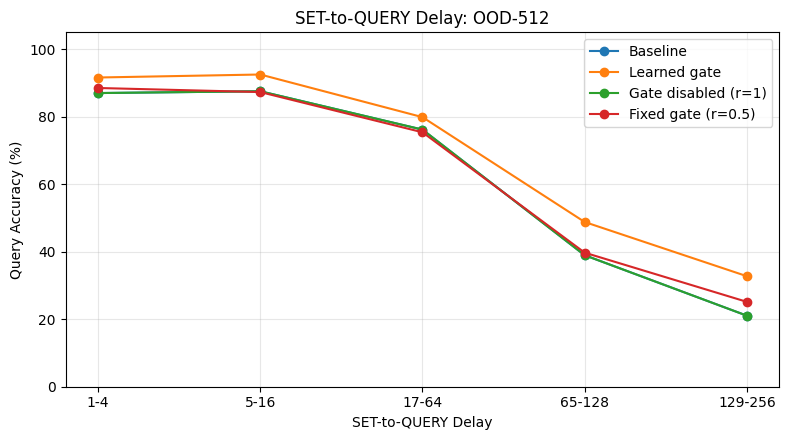

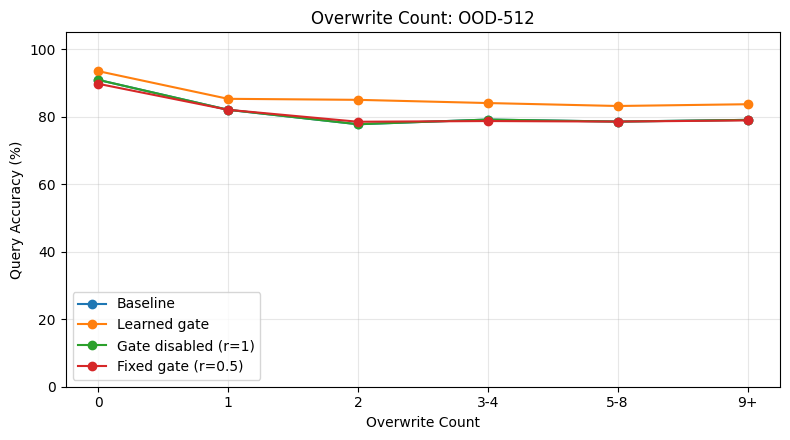

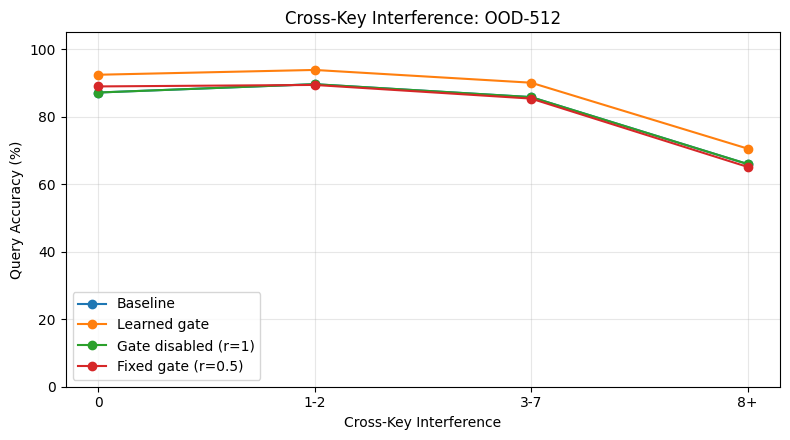

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

runs = {
    "Baseline": "seed42_baseline_2000",
    "Learned gate": "seed42_retention_2000",
    "Gate disabled (r=1)": "seed42_gate_disabled_2000",
    "Fixed gate (r=0.5)": "seed42_gate_fixed05_2000"
}

split = "test_ood_512"

metrics = {
    "delay": (
        "SET-to-QUERY Delay",
        ["1-4", "5-16", "17-64", "65-128", "129-256", "257+"]
    ),
    "overwrites_to_date": (
        "Overwrite Count",
        ["0", "1", "2", "3-4", "5-8", "9+"]
    ),
    "cross_key_interference": (
        "Cross-Key Interference",
        ["0", "1-2", "3-7", "8+"]
    )
}

for metric, (title, bins) in metrics.items():
    plt.figure(figsize=(8, 4.5))

    for name, folder in runs.items():
        path = Path("results") / folder / f"groups_{split}.csv"
        df = pd.read_csv(path, dtype={"group": str})
        df = df[df["metric"] == metric].copy()

        if metric == "overwrites_to_date":
            def overwrite_bin(n):
                n = int(n)
                if n <= 2:
                    return str(n)
                if n <= 4:
                    return "3-4"
                if n <= 8:
                    return "5-8"
                return "9+"

            df["group"] = df["group"].map(overwrite_bin)

        df = df.groupby("group", as_index=True)[
            ["correct", "count"]
        ].sum()

        accuracy = [
            100 * df.loc[b, "correct"] / df.loc[b, "count"]
            if b in df.index and df.loc[b, "count"] >= 30
            else float("nan")
            for b in bins
        ]

        plt.plot(bins, accuracy, marker="o", label=name)

    plt.title(f"{title}: OOD-512")
    plt.xlabel(title)
    plt.ylabel("Query Accuracy (%)")
    plt.ylim(0, 105)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

### **Grouped Evaluation Observations (OOD-512)**

**1. SET-to-QUERY Delay:** Accuracy decreases as the delay increases for all models. The learned retention gate consistently outperforms the baseline, with larger improvements at longer delays, particularly 65–256 steps. However, accuracy still declines substantially at long delays, indicating that retention remains challenging.

**2. Overwrite Count:** The learned gate achieves higher accuracy across all overwrite-count groups. Its performance remains relatively stable as overwrites increase, suggesting improved tracking of updated values without sacrificing overwrite correctness.

**3. Cross-Key Interference:** Accuracy decreases as more updates to other keys occur between SET and QUERY. The learned gate consistently performs better than the baseline, including under high interference, although it does not eliminate interference-related errors.

Across all three comparisons, the disabled gate closely matches the baseline, while the fixed gate provides limited benefit. These results support the advantage of learned, input-dependent retention over fixed retention.

### **Discussion and Research Questions (Seed 42)**

**1. Failure Modes:** The main failure is long-term forgetting. Accuracy decreases with SET-to-QUERY delay and cross-key interference, while the long-gap probe achieves only 23.0% accuracy with the learned gate. In contrast, overwrite-probe accuracy reaches 99.6%, indicating that recent updates are handled effectively. The results do not independently establish whether remaining errors arise from state loss or incorrect readout.

**2. Improvement and Trade-offs:** The learned retention gate improves accuracy across the evaluated conditions without an observed reduction in overwrite correctness. However, its improvement on the extreme long-gap probe is limited.

**3. Length Generalization:** Improvements persist beyond the training range of 32–128 tokens. The proposed model improves accuracy from 81.41% to 86.39% at length 256 and from 80.34% to 84.83% at length 512.

**4. Other Factors That May Affect the Results:** All models use the same datasets, training budget, optimizer settings, and evaluation protocol. The learned gate adds only 65 parameters (0.64%). The disabled-gate ablation reproduces baseline accuracy, while the fixed gate provides little benefit. These controls suggest a benefit from modifying retention dynamics, although the additional parameters and unmatched fixed-gate strength limit stronger causal conclusions. These preliminary seed-42 findings are followed by a three-seed evaluation to assess their consistency.

**5. Falsification:** H2 would be weakened if repeated experiments showed no consistent advantage over the disabled and fixed-gate controls on long-delay retrieval, or if improvements came at the expense of overwrite correctness. The current results support adaptive retention but do not prove that coupling through $\Delta_t$ causes the original failures.


# **MULTI-SEED EXPERIMENTS FOR A MORE RELIABLE ANALYSIS**

In [ ]:
import os
import sys
import json
import subprocess
from pathlib import Path
import torch

assert torch.cuda.is_available(), "Please enable a GPU runtime."

splits = [
    "val", "test_id", "test_ood_256", "test_ood_512",
    "stress_gap_512", "stress_overwrite_512"
]

variants = {
    "baseline": ("run_baseline.py", {}),
    "retention": ("run_retention.py", {}),
    "gate_disabled": (
        "run_retention.py", {"MAMBA_DISABLE_RETENTION": "1"}
    ),
    "gate_fixed05": (
        "run_retention.py", {"MAMBA_FIXED_RETENTION": "0.5"}
    ),
}

# Runs each experiment in a separate process.
# Measures peak CUDA memory without modifying training scripts.
worker = r"""
import sys, time, json, runpy
from pathlib import Path
import torch

script = sys.argv[1]
sys.argv = [script] + sys.argv[2:]
output_dir = Path(sys.argv[sys.argv.index("--output-dir") + 1])

torch.cuda.reset_peak_memory_stats()
start = time.perf_counter()

runpy.run_path(script, run_name="__main__")

torch.cuda.synchronize()

resource_metrics = {
    "gpu": torch.cuda.get_device_name(0),
    "peak_gpu_allocated_mb":
        round(torch.cuda.max_memory_allocated() / 1024**2, 2),
    "peak_gpu_reserved_mb":
        round(torch.cuda.max_memory_reserved() / 1024**2, 2),
    "total_runtime_seconds":
        round(time.perf_counter() - start, 2),
    "memory_scope": "training_and_evaluation"
}

(output_dir / "resource_metrics.json").write_text(
    json.dumps(resource_metrics, indent=2)
)
print("RESOURCE METRICS:", resource_metrics)
"""

for seed in [43, 44]:
    for name, (script, extra_env) in variants.items():

        output_dir = Path("results") / f"seed{seed}_{name}_2000"
        checkpoint = "baseline.pt" if name == "baseline" else "retention.pt"

        expected_files = [
            output_dir / checkpoint,
            output_dir / "resource_metrics.json",
        ] + [
            output_dir / f"metrics_{split}.json"
            for split in splits
        ] + [
            output_dir / f"groups_{split}.csv"
            for split in splits
        ]

        if all(p.exists() for p in expected_files):
            print(f"SKIPPING completed: {name}, seed {seed}", flush=True)
            continue

        if output_dir.exists():
            raise RuntimeError(
                f"Incomplete output folder exists: {output_dir}. "
                "Inspect it before rerunning to avoid overwriting results."
            )

        output_dir.mkdir(parents=True)
        log_path = output_dir / "training.log"

        env = os.environ.copy()
        env.pop("MAMBA_DISABLE_RETENTION", None)
        env.pop("MAMBA_FIXED_RETENTION", None)
        env.update(extra_env)

        command = [
            sys.executable, "-u", "-c", worker, script,
            "--steps", "2000",
            "--batch-size", "16",
            "--eval-batch-size", "4",
            "--lr", "0.001",
            "--seed", str(seed),
            "--device", "cuda",
            "--output-dir", str(output_dir),
            "--eval-splits", *splits
        ]

        print(f"\nRUNNING: {name} | Seed {seed}", flush=True)

        with log_path.open("w") as log:
            result = subprocess.run(
                command,
                env=env,
                stdout=log,
                stderr=subprocess.STDOUT
            )

        if result.returncode != 0:
            print("\n".join(log_path.read_text().splitlines()[-30:]))
            raise RuntimeError(f"Run failed: {name}, seed {seed}")

        resources = json.loads(
            (output_dir / "resource_metrics.json").read_text()
        )

        print(
            f"COMPLETED | "
            f"Peak GPU: {resources['peak_gpu_allocated_mb']:.2f} MB | "
            f"Runtime: {resources['total_runtime_seconds']:.1f}s",
            flush=True
        )

        for split in splits:
            metrics = json.loads(
                (output_dir / f"metrics_{split}.json").read_text()
            )
            print(f"  {split}: {metrics['query_accuracy']:.4f}")

print("\nAll additional seed experiments completed.")


RUNNING: baseline | Seed 43
COMPLETED | Peak GPU: 43.21 MB | Runtime: 246.2s
  val: 0.8679
  test_id: 0.8371
  test_ood_256: 0.8045
  test_ood_512: 0.7750
  stress_gap_512: 0.7766
  stress_overwrite_512: 0.7824

RUNNING: retention | Seed 43
COMPLETED | Peak GPU: 44.23 MB | Runtime: 237.8s
  val: 0.9285
  test_id: 0.9041
  test_ood_256: 0.8819
  test_ood_512: 0.8604
  stress_gap_512: 0.8545
  stress_overwrite_512: 0.8583

RUNNING: gate_disabled | Seed 43
COMPLETED | Peak GPU: 43.72 MB | Runtime: 231.7s
  val: 0.8679
  test_id: 0.8371
  test_ood_256: 0.8045
  test_ood_512: 0.7750
  stress_gap_512: 0.7766
  stress_overwrite_512: 0.7824

RUNNING: gate_fixed05 | Seed 43
COMPLETED | Peak GPU: 43.72 MB | Runtime: 230.2s
  val: 0.9033
  test_id: 0.8776
  test_ood_256: 0.8553
  test_ood_512: 0.8334
  stress_gap_512: 0.8327
  stress_overwrite_512: 0.8339

RUNNING: baseline | Seed 44
COMPLETED | Peak GPU: 43.21 MB | Runtime: 227.7s
  val: 0.8596
  test_id: 0.8271
  test_ood_256: 0.7902
  test_oo

## **Aggregating Results**

In [ ]:
# Multi-seed aggregation (3 seeds × 4 variants)

import json
from pathlib import Path
import pandas as pd

ROOT = Path("results")
OUT = ROOT / "multiseed_summary"
OUT.mkdir(parents=True, exist_ok=True)

SEEDS = [42, 43, 44]

VARIANTS = {
    "Baseline": "baseline",
    "Learned gate": "retention",
    "Gate disabled (r=1)": "gate_disabled",
    "Fixed gate (r=0.5)": "gate_fixed05",
}

SPLITS = [
    "val",
    "test_id",
    "test_ood_256",
    "test_ood_512",
    "stress_gap_512",
    "stress_overwrite_512",
]

overall_rows = []
group_rows = []
resource_rows = []

# 1. Read all seed-level results
for model, variant in VARIANTS.items():
    for seed in SEEDS:

        folder = ROOT / f"seed{seed}_{variant}_2000"

        for split in SPLITS:
            metrics_path = folder / f"metrics_{split}.json"
            groups_path = folder / f"groups_{split}.csv"

            if not metrics_path.exists() or not groups_path.exists():
                raise FileNotFoundError(
                    f"Missing results for {model}, seed {seed}, "
                    f"split {split}: {folder}"
                )

            with open(metrics_path) as f:
                m = json.load(f)

            overall_rows.append({
                "model": model,
                "seed": seed,
                "split": split,
                "accuracy_pct": 100 * m["query_accuracy"],
                "probe_accuracy_pct": (
                    100 * m["probe_accuracy"]
                    if m["probe_accuracy"] is not None
                    else float("nan")
                ),
                "num_queries": m["num_queries"],
                "num_sequences": m["num_sequences"],
                "evaluation_seconds": m["evaluation_seconds"],
                "queries_per_second": m["queries_per_second"],
            })

            g = pd.read_csv(groups_path, dtype={"group": str})
            g["model"] = model
            g["seed"] = seed
            group_rows.append(g)

        resource_path = folder / "resource_metrics.json"
        if resource_path.exists():
            r = json.loads(resource_path.read_text())
            resource_rows.append({
                "model": model,
                "seed": seed,
                **r
            })

overall = pd.DataFrame(overall_rows)
groups = pd.concat(group_rows, ignore_index=True)

# 2. Verify fixed evaluation sizes across all models and seeds
assert overall.groupby("split")["num_queries"].nunique().eq(1).all(), \
    "Query counts differ across evaluation runs."

assert overall.groupby("split")["num_sequences"].nunique().eq(1).all(), \
    "Evaluation dataset sizes differ across runs."

assert overall.groupby(["model", "split"])["seed"].nunique().eq(3).all(), \
    "Some models or splits do not have all three seeds."

# 3. Compute mean ± sample standard deviation
summary = (
    overall.groupby(["model", "split"], as_index=False)
    .agg(
        mean_pct=("accuracy_pct", "mean"),
        std_pct=("accuracy_pct", "std"),
        n_seeds=("seed", "nunique"),
    )
)

summary["mean ± std (%)"] = summary.apply(
    lambda r: f"{r['mean_pct']:.2f} ± {r['std_pct']:.2f}",
    axis=1
)

# 4. Overall accuracy comparison table
comparison = summary.pivot(
    index="model",
    columns="split",
    values="mean ± std (%)"
)

comparison = comparison.reindex(
    index=list(VARIANTS),
    columns=SPLITS
)

print("\nOVERALL QUERY ACCURACY: MEAN ± STD (%)")
display(comparison)

# 5. Stress-test focused-probe accuracy
probes = overall.dropna(subset=["probe_accuracy_pct"])

probe_summary = (
    probes.groupby(["model", "split"], as_index=False)
    .agg(
        mean_pct=("probe_accuracy_pct", "mean"),
        std_pct=("probe_accuracy_pct", "std"),
    )
)

probe_summary["mean ± std (%)"] = probe_summary.apply(
    lambda r: f"{r['mean_pct']:.2f} ± {r['std_pct']:.2f}",
    axis=1
)

probe_table = probe_summary.pivot(
    index="model",
    columns="split",
    values="mean ± std (%)"
).reindex(index=list(VARIANTS))

print("\nFOCUSED STRESS-PROBE ACCURACY: MEAN ± STD (%)")
display(probe_table)

# 6. Resource measurements
if resource_rows:
    resources = pd.DataFrame(resource_rows)
    resources.to_csv(OUT / "seed_level_resources.csv", index=False)

    print("\nGPU RESOURCE MEASUREMENTS (RECORDED SEEDS)")
    display(resources)

# 7. Save numeric data for
overall.to_csv(OUT / "seed_level_overall.csv", index=False)
summary.to_csv(OUT / "summary_overall.csv", index=False)
groups.to_csv(OUT / "seed_level_groups.csv", index=False)
probe_summary.to_csv(OUT / "summary_probes.csv", index=False)

comparison.to_csv(OUT / "comparison_table.csv")
probe_table.to_csv(OUT / "probe_comparison_table.csv")

print("\nAggregation complete: 4 models × 3 seeds × 6 splits.")
print(f"Files saved to: {OUT.resolve()}")


OVERALL QUERY ACCURACY: MEAN ± STD (%)


split,val,test_id,test_ood_256,test_ood_512,stress_gap_512,stress_overwrite_512
model,,,,,,
Baseline,87.02 ± 1.19,83.72 ± 1.01,80.30 ± 1.20,78.15 ± 1.94,77.97 ± 1.55,78.20 ± 1.75
Learned gate,92.04 ± 0.72,89.63 ± 0.69,87.23 ± 0.90,85.43 ± 0.60,85.01 ± 0.55,85.34 ± 0.48
Gate disabled (r=1),87.02 ± 1.19,83.72 ± 1.01,80.30 ± 1.20,78.15 ± 1.94,77.97 ± 1.55,78.20 ± 1.75
Fixed gate (r=0.5),88.95 ± 1.29,85.77 ± 1.73,83.26 ± 2.09,81.26 ± 1.80,81.00 ± 1.97,81.03 ± 2.04



FOCUSED STRESS-PROBE ACCURACY: MEAN ± STD (%)


split,stress_gap_512,stress_overwrite_512
model,,
Baseline,24.60 ± 2.43,96.60 ± 2.31
Learned gate,22.87 ± 2.20,99.53 ± 0.12
Gate disabled (r=1),24.60 ± 2.43,96.60 ± 2.31
Fixed gate (r=0.5),23.47 ± 2.27,98.60 ± 1.06



GPU RESOURCE MEASUREMENTS (RECORDED SEEDS)


,model,seed,gpu,peak_gpu_allocated_mb,peak_gpu_reserved_mb,total_runtime_seconds,memory_scope
0,Baseline,43,Tesla T4,43.21,74.0,246.19,training_and_evaluation
1,Baseline,44,Tesla T4,43.21,74.0,227.72,training_and_evaluation
2,Learned gate,43,Tesla T4,44.23,74.0,237.81,training_and_evaluation
3,Learned gate,44,Tesla T4,44.23,74.0,230.87,training_and_evaluation
4,Gate disabled (r=1),43,Tesla T4,43.72,74.0,231.70,training_and_evaluation
5,Gate disabled (r=1),44,Tesla T4,43.72,74.0,234.26,training_and_evaluation
6,Fixed gate (r=0.5),43,Tesla T4,43.72,74.0,230.17,training_and_evaluation
7,Fixed gate (r=0.5),44,Tesla T4,43.72,74.0,229.53,training_and_evaluation



Aggregation complete: 4 models × 3 seeds × 6 splits.
Files saved to: /content/mamba-minimal/results/multiseed_summary


# **Multi-seed comparison plots**

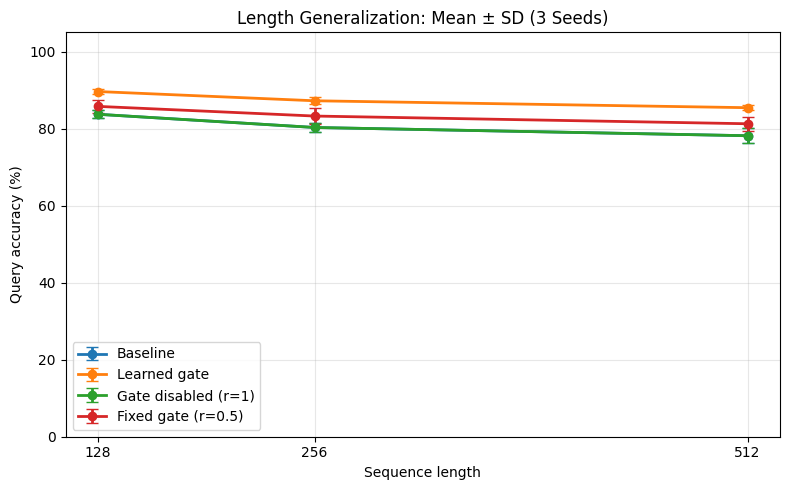

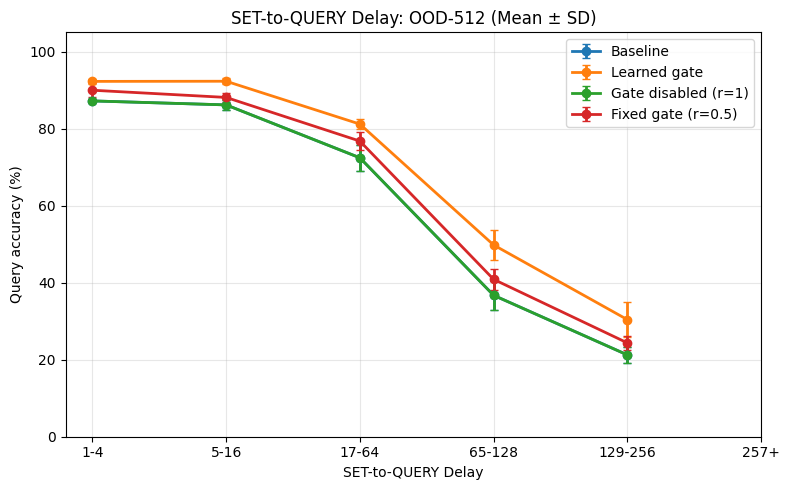

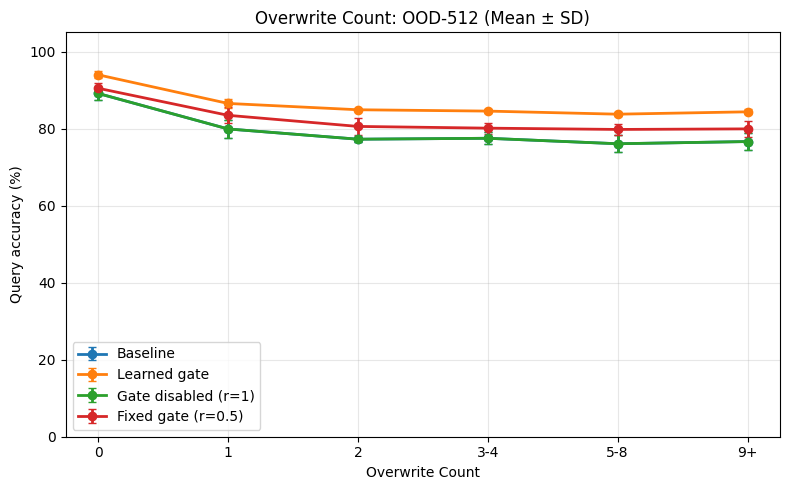

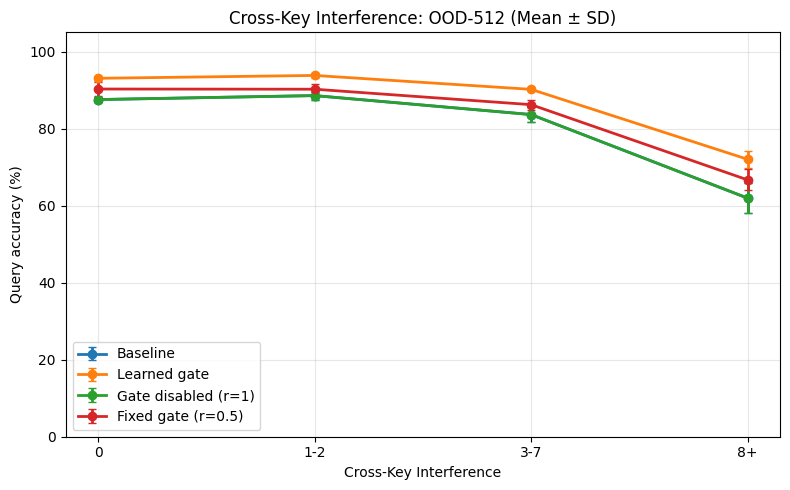

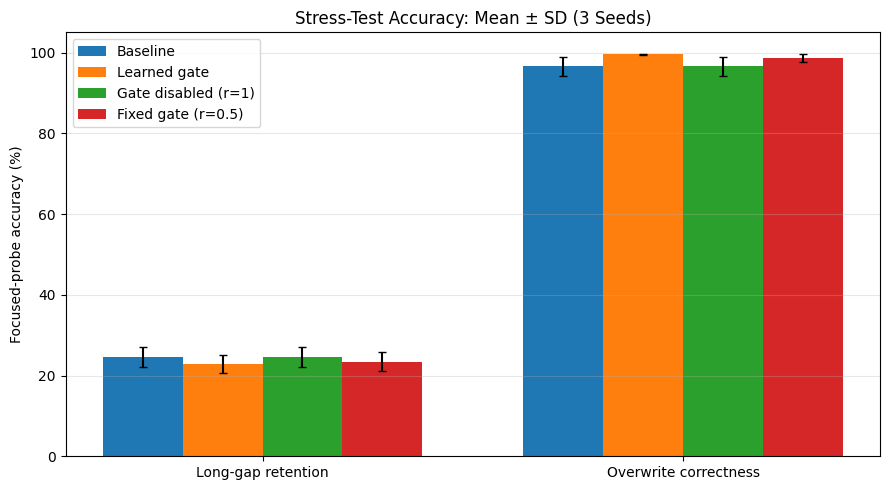

All 5 plots saved to: /content/mamba-minimal/results/multiseed_summary


In [ ]:
# Multi-seed comparison plots
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

OUT = Path("results/multiseed_summary")
overall = pd.read_csv(OUT / "seed_level_overall.csv")
groups = pd.read_csv(
    OUT / "seed_level_groups.csv",
    dtype={"group": str}
)

models = [
    "Baseline",
    "Learned gate",
    "Gate disabled (r=1)",
    "Fixed gate (r=0.5)"
]

def save_plot(filename):
    plt.tight_layout()
    plt.savefig(OUT / filename, dpi=300, bbox_inches="tight")
    plt.show()

def mean_std(df, value):
    vals = df[value].dropna()
    if len(vals) != 3:
        return np.nan, np.nan
    return vals.mean(), vals.std(ddof=1)


# --------------------------------------------------
# PLOT 1: Accuracy by sequence length
# --------------------------------------------------

splits = ["test_id", "test_ood_256", "test_ood_512"]
x = np.array([128, 256, 512])

plt.figure(figsize=(8, 5))

for model in models:
    means, stds = [], []

    for split in splits:
        d = overall[
            (overall.model == model) &
            (overall.split == split)
        ]
        m, s = mean_std(d, "accuracy_pct")
        means.append(m)
        stds.append(s)

    plt.errorbar(
        x, means, yerr=stds,
        marker="o", capsize=4, linewidth=2,
        label=model
    )

plt.xlabel("Sequence length")
plt.ylabel("Query accuracy (%)")
plt.title("Length Generalization: Mean ± SD (3 Seeds)")
plt.xticks(x)
plt.ylim(0, 105)
plt.grid(alpha=0.3)
plt.legend()
save_plot("multiseed_length.png")


# --------------------------------------------------
# Helper for grouped metrics
# --------------------------------------------------

def plot_grouped(metric, bins, title, filename,
                 split="test_ood_512", overwrite=False):

    df = groups[
        (groups["split"] == split) &
        (groups["metric"] == metric)
    ].copy()

    if overwrite:
        def overwrite_bin(value):
            n = int(value)
            if n <= 2:
                return str(n)
            if n <= 4:
                return "3-4"
            if n <= 8:
                return "5-8"
            return "9+"

        df["group"] = df["group"].map(overwrite_bin)

    df = (
        df.groupby(["model", "seed", "group"], as_index=False)
        [["correct", "count"]].sum()
    )

    df["accuracy_pct"] = 100 * df["correct"] / df["count"]

    plt.figure(figsize=(8, 5))

    for model in models:
        means, stds = [], []

        for b in bins:
            d = df[
                (df.model == model) &
                (df.group == b) &
                (df["count"] >= 30)
            ]

            m, s = mean_std(d, "accuracy_pct")
            means.append(m)
            stds.append(s)

        plt.errorbar(
            np.arange(len(bins)),
            means, yerr=stds,
            marker="o", capsize=3,
            linewidth=2, label=model
        )

    plt.xticks(np.arange(len(bins)), bins)
    plt.xlabel(title)
    plt.ylabel("Query accuracy (%)")
    plt.title(f"{title}: OOD-512 (Mean ± SD)")
    plt.ylim(0, 105)
    plt.grid(alpha=0.3)
    plt.legend()
    save_plot(filename)


# --------------------------------------------------
# PLOT 2: Accuracy by SET-to-QUERY delay
# --------------------------------------------------

plot_grouped(
    "delay",
    ["1-4", "5-16", "17-64", "65-128", "129-256", "257+"],
    "SET-to-QUERY Delay",
    "multiseed_delay.png"
)


# --------------------------------------------------
# PLOT 3: Accuracy by overwrite count
# --------------------------------------------------

plot_grouped(
    "overwrites_to_date",
    ["0", "1", "2", "3-4", "5-8", "9+"],
    "Overwrite Count",
    "multiseed_overwrite.png",
    overwrite=True
)


# --------------------------------------------------
# PLOT 4: Accuracy by cross-key interference
# --------------------------------------------------

plot_grouped(
    "cross_key_interference",
    ["0", "1-2", "3-7", "8+"],
    "Cross-Key Interference",
    "multiseed_interference.png"
)


# --------------------------------------------------
# PLOT 5: Focused stress-probe accuracy
# --------------------------------------------------

stress_splits = ["stress_gap_512", "stress_overwrite_512"]
labels = ["Long-gap retention", "Overwrite correctness"]

x = np.arange(len(labels))
width = 0.19

fig, ax = plt.subplots(figsize=(9, 5))

for i, model in enumerate(models):
    means, stds = [], []

    for split in stress_splits:
        d = overall[
            (overall.model == model) &
            (overall.split == split)
        ]

        m, s = mean_std(d, "probe_accuracy_pct")
        means.append(m)
        stds.append(s)

    ax.bar(
        x + (i - 1.5) * width,
        means,
        width,
        yerr=stds,
        capsize=3,
        label=model
    )

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel("Focused-probe accuracy (%)")
ax.set_title("Stress-Test Accuracy: Mean ± SD (3 Seeds)")
ax.set_ylim(0, 105)
ax.legend()
ax.grid(axis="y", alpha=0.3)

save_plot("multiseed_stress_probes.png")

print(f"All 5 plots saved to: {OUT.resolve()}")


### Multi-Seed Results and Failure Analysis

We evaluated four configurations across three seeds (42, 43, 44), using identical datasets, 2,000 optimizer updates, and matched training settings.

The learned retention gate consistently improves overall query accuracy over the original Mamba-1:

- **ID-128:** 83.72% to 89.63% (+5.91 percentage points).
- **OOD-256:** 80.30% to 87.23% (+6.93 points).
- **OOD-512:** 78.15% to 85.43% (+7.28 points).

The disabled gate reproduces the baseline results. The fixed gate ($r_t=0.5$) achieves 81.26% on OOD-512, compared with 85.43% for the learned gate.

**Failure-mode analysis.** Accuracy decreases with increasing SET-to-QUERY delay and cross-key interference. The learned gate improves performance across the reported delay and interference groups, but substantial degradation remains at long delays.

On the designated 511-step long-gap probe, accuracy remains near chance: 24.60 ± 2.43% for the baseline and 22.87 ± 2.20% for the learned gate. In contrast, overwrite-probe accuracy improves from 96.60 ± 2.31% to 99.53 ± 0.12%.

These results indicate that the proposed gate improves general state tracking and preserves overwrite correctness, but does not resolve extreme long-horizon retrieval.


In [ ]:
# Inspect learned retention gate values

import torch
import numpy as np
from pathlib import Path
import run_retention as rt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

for seed in [42, 43, 44]:
    ckpt_path = Path(f"results/seed{seed}_retention_2000/retention.pt")

    if not ckpt_path.exists():
        print(f"Seed {seed}: checkpoint not available yet")
        continue

    model = rt.StateTracker(Path(".")).to(device)
    ckpt = torch.load(ckpt_path, map_location="cpu", weights_only=True)
    model.load_state_dict(ckpt["model_state"])
    model.eval()

    gate = model.backbone.layers[0].mixer.retention_proj

    print(f"\n{'='*55}")
    print(f"LEARNED GATE: SEED {seed}")
    print(f"{'='*55}")
    print(f"Weight norm: {gate.weight.norm().item():.6f}")
    print(f"Bias:        {gate.bias.item():.6f}")
    print(f"Initial gate value: {torch.sigmoid(torch.tensor(3.0)).item():.6f}")

    captured = {}

    def capture_gate(module, inputs, output):
        captured["r"] = torch.sigmoid(output.detach()).cpu()[0, :, 0]

    handle = gate.register_forward_hook(capture_gate)

    for split in ["test_id", "stress_gap_512"]:
        dataset = rt.EventDataset(Path("dataset") / f"{split}.jsonl.gz")

        values = {"SET": [], "QUERY": [], "NOOP": []}

        # Sample 20 sequences per split
        with torch.no_grad():
            for i in range(min(20, len(dataset))):
                tokens, _ = dataset[i]
                model(tokens.unsqueeze(0).to(device))

                r = captured["r"].numpy()
                ids = tokens.numpy()

                values["SET"].extend(r[(ids >= 1) & (ids <= 32)])
                values["QUERY"].extend(r[ids >= 33])
                values["NOOP"].extend(r[ids == 0])

        print(f"\n{split} (20 sampled sequences)")
        print(f"{'Event':<10} {'Mean':>9} {'Std':>9} {'Min':>9} {'Max':>9}")

        for event, v in values.items():
            v = np.asarray(v)
            if len(v):
                print(
                    f"{event:<10} "
                    f"{v.mean():>9.4f} "
                    f"{v.std():>9.4f} "
                    f"{v.min():>9.4f} "
                    f"{v.max():>9.4f}"
                )

    handle.remove()
    del model




LEARNED GATE: SEED 42
Weight norm: 2.957608
Bias:        2.389081
Initial gate value: 0.952574

test_id (20 sampled sequences)
Event           Mean       Std       Min       Max
SET           0.0389    0.0425    0.0010    0.4296
QUERY         0.0240    0.0298    0.0013    0.2132
NOOP          0.0323    0.0281    0.0033    0.3495

stress_gap_512 (20 sampled sequences)
Event           Mean       Std       Min       Max
SET           0.0390    0.0432    0.0005    0.4949
QUERY         0.0212    0.0240    0.0009    0.3153
NOOP          0.0316    0.0258    0.0016    0.3256

LEARNED GATE: SEED 43
Weight norm: 2.981882
Bias:        2.400455
Initial gate value: 0.952574

test_id (20 sampled sequences)
Event           Mean       Std       Min       Max
SET           0.0453    0.0414    0.0003    0.3386
QUERY         0.0136    0.0115    0.0002    0.0940
NOOP          0.0182    0.0159    0.0004    0.1389

stress_gap_512 (20 sampled sequences)
Event           Mean       Std       Min       Max
SET


### Interpretation, Limitations, and Next Experiment

**Learned gate behavior.** Across three seeds, the mean gate values for SET, QUERY, and NOOP events are approximately 0.01–0.05 on the sampled ID-128 sequences, substantially below the initial value of 0.953. This indicates strong suppression of state decay.

**Hypothesis assessment.** H1 is supported by the observed decrease in retrieval accuracy with increasing delay. H2 is partially supported: the learned gate improves overall accuracy, but extreme long-gap retrieval remains near chance.

**Limitations.** The fixed-gate ablation uses $r_t=0.5$, whereas the learned gate typically produces much smaller values. Therefore, the observed improvement cannot be attributed conclusively to input-dependent gating rather than stronger decay suppression. A fixed gate near 0.03 would provide a more informative control.

**Primary bottleneck.** The results suggest that reducing state decay alone is insufficient. Cross-key interference and limited retrieval capability remain plausible explanations, but the present experiments cannot conclusively distinguish them.

**Next experiment.** We would compare retrieval at identical SET-to-QUERY delays under two conditions:

1. Intervening NOOP events only.
2. Intervening SET operations on other keys.

Using the same trained checkpoints would help isolate distractor interference from delay-related forgetting. A substantial accuracy difference would support cross-key interference as a contributor to long-horizon failure.
